In [33]:
import yfinance as yf
# from yahooquery import Ticker
import requests
import matplotlib.pyplot as plt
import numpy as np
import math
import pickle
from datetime import datetime

In [34]:
def time_elapsed(start_time, end_time):
    if not isinstance(start_time, datetime) or not isinstance(end_time, datetime):
        return None
    elapsed_time = end_time - start_time
    return elapsed_time.days  # Return the number of days

In [35]:
stock_ticker = ['AMD', 'PLTR', 'SPCX', 'LITE', 'MRNA', 'KOD', 'TSM', 'META', 'KO', 'MU', 'MRVL', 'DELL']

In [36]:
stock_name = yf.download(stock_ticker, start='2009-01-01', auto_adjust=False)

stock_info = {}
for ticker_symbol in stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]:
    try:
        info = yf.Ticker(ticker_symbol).info
        stock_info[ticker_symbol] = info
        print(f"Stock: {info.get('longName', ticker_symbol)} ({ticker_symbol})")
    except Exception as e:
        print(f"Could not fetch company name for {ticker_symbol}: {e}")


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
[                       0%                       ]c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.o

Stock: Advanced Micro Devices, Inc. (AMD)
Stock: Palantir Technologies Inc. (PLTR)
Stock: Space Exploration Technologies Corp. (SPCX)
Stock: Lumentum Holdings Inc. (LITE)
Stock: Moderna, Inc. (MRNA)
Stock: Kodiak Sciences Inc. (KOD)
Stock: Taiwan Semiconductor Manufacturing Company Limited (TSM)
Stock: Meta Platforms, Inc. (META)
Stock: The Coca-Cola Company (KO)
Stock: Micron Technology, Inc. (MU)
Stock: Marvell Technology, Inc. (MRVL)
Stock: Dell Technologies Inc. (DELL)


In [37]:
display(stock_name)

Price        Adj Close                                                 \
Ticker             AMD        DELL         KO         KOD        LITE   
Date                                                                    
2009-01-02    2.380000         NaN  13.299511         NaN         NaN   
2009-01-05    2.670000         NaN  13.166225         NaN         NaN   
2009-01-06    2.780000         NaN  12.954710         NaN         NaN   
2009-01-07    2.660000         NaN  13.018458         NaN         NaN   
2009-01-08    2.740000         NaN  13.108280         NaN         NaN   
...                ...         ...        ...         ...         ...   
2026-11-03  483.899994  408.399994  94.800003   98.889999  680.159973   
2026-11-04  488.779999  372.359985  95.800003   98.510002  626.750000   
2026-11-05  404.399994  316.910004  95.730003   91.019997  509.700012   
2026-11-06  449.040009  328.529999  95.669998   99.300003  538.590027   
2026-11-09  508.579987  346.309998  96.029999  107.099998  596.159973   

Price                                                                   ...  \
Ticker            META        MRNA        MRVL          MU        PLTR  ...   
Date                                                                    ...   
2009-01-02         NaN         NaN    6.050562    2.768954         NaN  ...   
2009-01-05         NaN         NaN    5.973972    3.236946         NaN  ...   
2009-01-06         NaN         NaN    6.501587    3.383194         NaN  ...   
2009-01-07         NaN         NaN    6.220760    3.197946         NaN  ...   
2009-01-08         NaN         NaN    6.195231    3.324695         NaN  ...   
...                ...         ...         ...         ...         ...  ...   
2026-11-03  621.030029  228.440002  171.970001  855.099976  175.399994  ...   
2026-11-04  630.000000  258.380005  159.800003  795.229980  171.699997  ...   
2026-11-05  605.080017  241.460007  133.550003  656.390015  154.990005  ...   
2026-11-06  610.150024  254.190002  141.199997  690.000000  160.380005  ...   
2026-11-09  641.369995  269.000000  154.600006  733.150024  169.199997  ...   

Price         Volume                                                           \
Ticker            KO        KOD        LITE        META        MRNA      MRVL   
Date                                                                            
2009-01-02  16355800        NaN         NaN         NaN         NaN  10972000   
2009-01-05  20237200        NaN         NaN         NaN         NaN  12329400   
2009-01-06  21307800        NaN         NaN         NaN         NaN  17849300   
2009-01-07  21581000        NaN         NaN         NaN         NaN  14302000   
2009-01-08  20087000        NaN         NaN         NaN         NaN  10463000   
...              ...        ...         ...         ...         ...       ...   
2026-11-03  16107100   803300.0   7164700.0  13731300.0   9515700.0  39412100   
2026-11-04  27088300  1004000.0   9546900.0  32441800.0  14808300.0  46568100   
2026-11-05  31053500  1100700.0  10038000.0  28676200.0  12032000.0  66645300   
2026-11-06  18420100  1049900.0   5406000.0  15705500.0  16329100.0  33562100   
2026-11-09  16640400  1128100.0   6043900.0  19106400.0  12332700.0  33517400   

Price                                                    
Ticker            MU        PLTR         SPCX       TSM  
Date                                                     
2009-01-02  17537200         NaN          NaN   9887190  
2009-01-05  36158500         NaN          NaN  13504888  
2009-01-06  30659700         NaN          NaN  17119773  
2009-01-07  25676100         NaN          NaN  21746692  
2009-01-08  23386700         NaN          NaN  16472251  
...              ...         ...          ...       ...  
2026-11-03  21286500  53062500.0   73242000.0   9421100  
2026-11-04  35906100  35044600.0  135443400.0  14516500  
2026-11-05  77872700  50014300.0  171356200.0  43030700  
2026-11-06  44887900  24335100.0  11549

In [38]:
simulation_ticker = stock_ticker[0] if isinstance(stock_ticker, (list, tuple)) else stock_ticker
close_prices = stock_name[('Close', simulation_ticker)].dropna()

In [39]:
display(close_prices)

Date
2009-01-02      2.380000
2009-01-05      2.670000
2009-01-06      2.780000
2009-01-07      2.660000
2009-01-08      2.740000
                 ...    
2026-11-03    483.899994
2026-11-04    488.779999
2026-11-05    404.399994
2026-11-06    449.040009
2026-11-09    508.579987
Name: (Close, AMD), Length: 4491, dtype: float64

In [40]:
# Total growth = last price / first price
total_growth = close_prices.iloc[-1] / close_prices.iloc[0]

In [41]:
print(total_growth)

213.68905971323255


In [42]:
# Current price / first record (e.g., price at the beginning of 2009)
# provides us with the total growth %

# Next, we want to annualize this percentage
# First, we convert our time elapsed to the number of years elapsed
number_of_days = time_elapsed(stock_name.index[0], stock_name.index[-1])
number_of_years = number_of_days / 365.0  # Assuming 365 days per year

In [43]:
print(number_of_days)
print(number_of_years)

6520
17.863013698630137


In [44]:
print(stock_name.index[0])
print(stock_name.index[-1])

2009-01-02 00:00:00
2026-11-09 00:00:00


In [45]:
simulation_ticker = stock_ticker[0] if isinstance(stock_ticker, (list, tuple)) else stock_ticker
close_prices = stock_name[('Close', simulation_ticker)].dropna()

# Second, we can raise the total growth to the inverse of the number of years
# (e.g., ~1/10 at the time of writing) to annualize our growth rate
cagr = (close_prices.iloc[-1] / close_prices.iloc[0]) ** (1/number_of_years) - 1

# Calculate the annualized standard deviation of daily price changes.
number_of_trading_days = 252
std_dev = close_prices.pct_change().std() * math.sqrt(number_of_trading_days)

# Guard against missing data or a zero-priced series.
if close_prices.empty or not np.isfinite(cagr) or not np.isfinite(std_dev):
    raise ValueError(f"Cannot simulate {simulation_ticker}: insufficient or invalid price data")

# Calculate daily return percentages for 1 year's worth of trading (252 days).
daily_return_percentages = np.random.normal(
    cagr / number_of_trading_days,
    std_dev / math.sqrt(number_of_trading_days),
    number_of_trading_days
) + 1

# Apply the daily returns to the most recent price as a random walk.
price_series = [float(close_prices.iloc[-1])]
for daily_return in daily_return_percentages:
    price_series.append(price_series[-1] * daily_return)

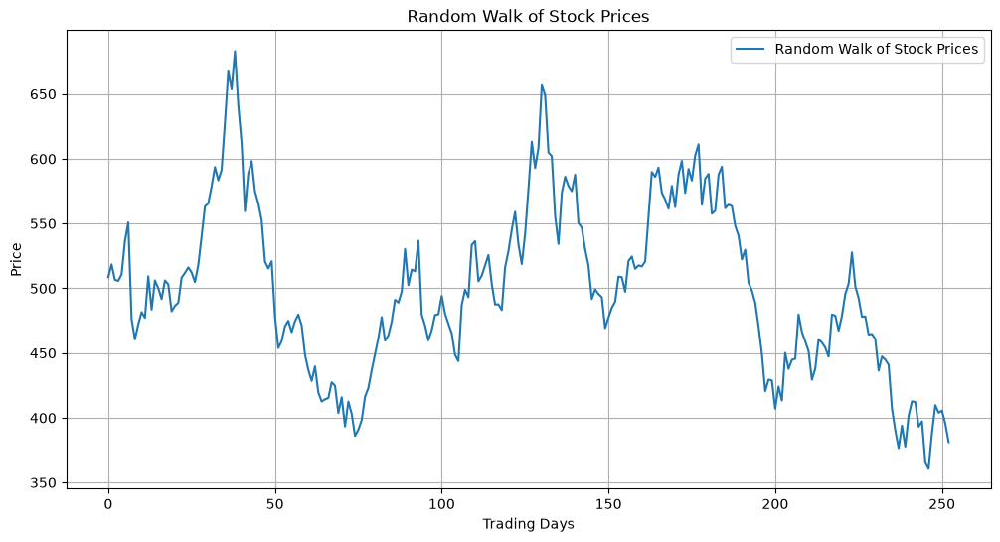

In [46]:
# Plot a single 'random walk' of stock prices
plt.figure(figsize=(12, 6))
plt.plot(price_series, label='Random Walk of Stock Prices')
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walk of Stock Prices')
plt.legend()
plt.grid(True)
plt.show()

# Now that we've created a single random walk above,
# we can simulate this process over a large sample size to
# get a better sense of the true expected distribution
number_of_trials = 3000

# Set up an additional array to collect all possible
# closing prices on the last day of the window.
# We can use this for a histogram to get a clearer sense of possible outcomes
closing_prices = []


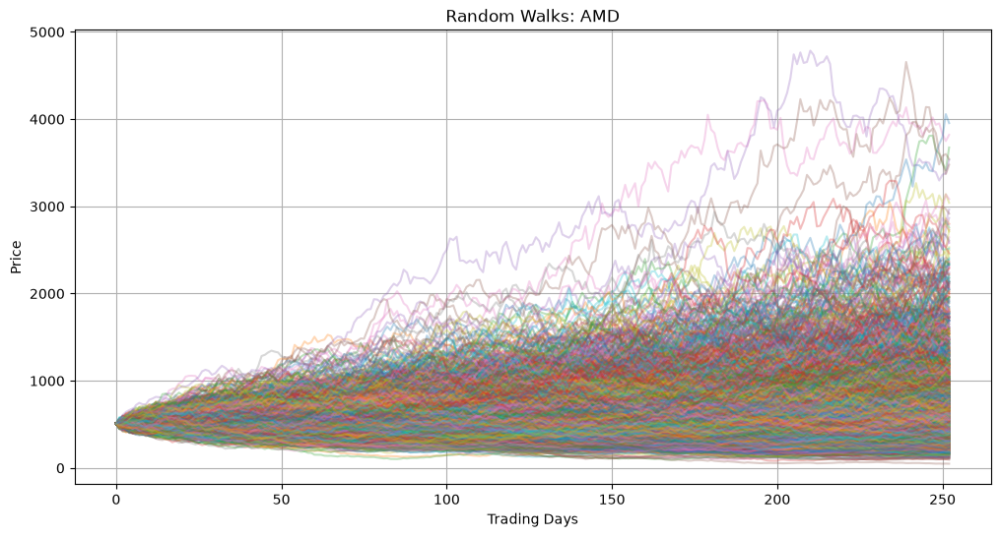

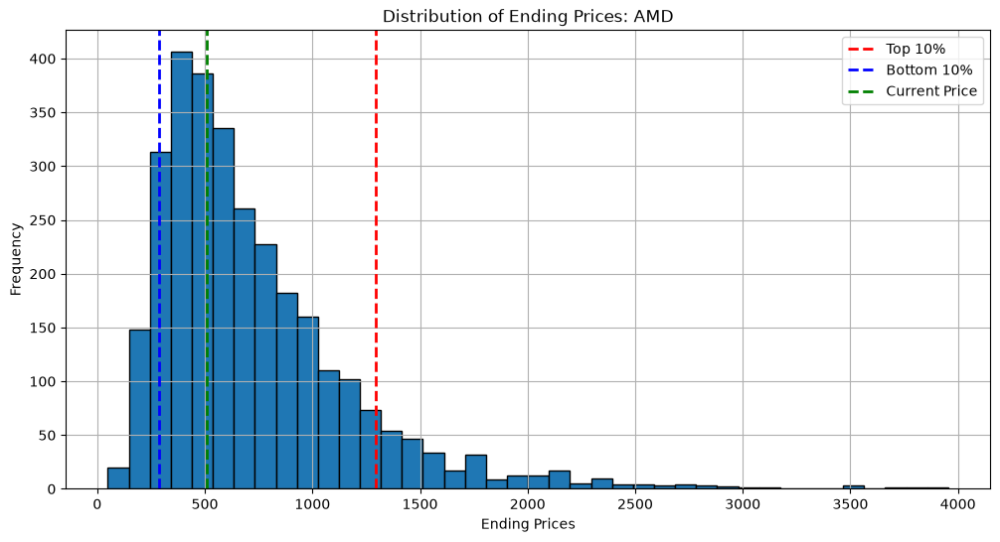

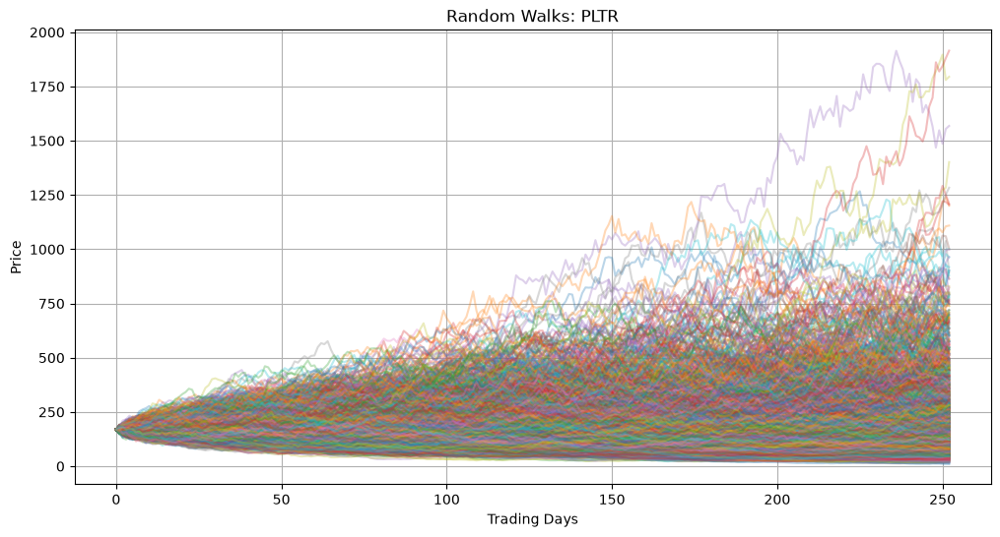

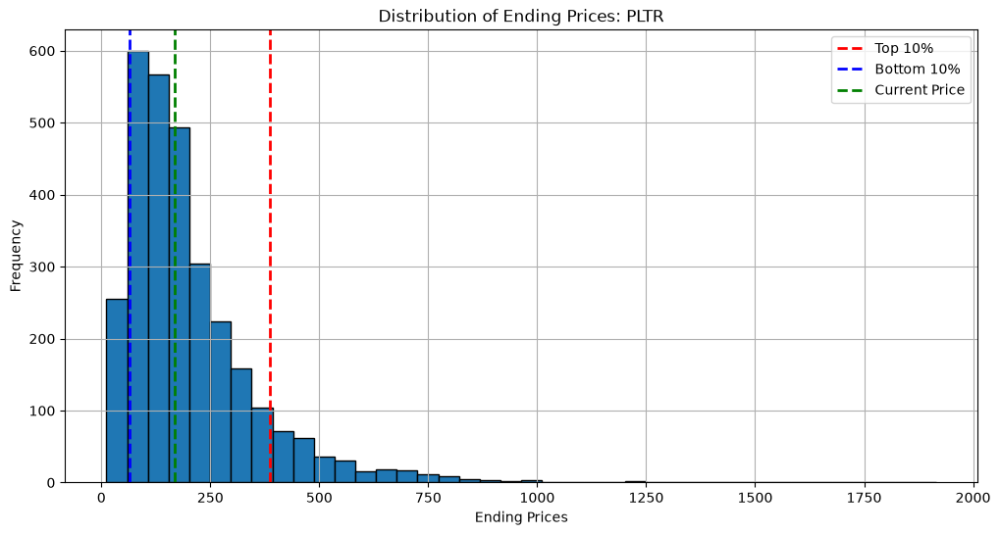

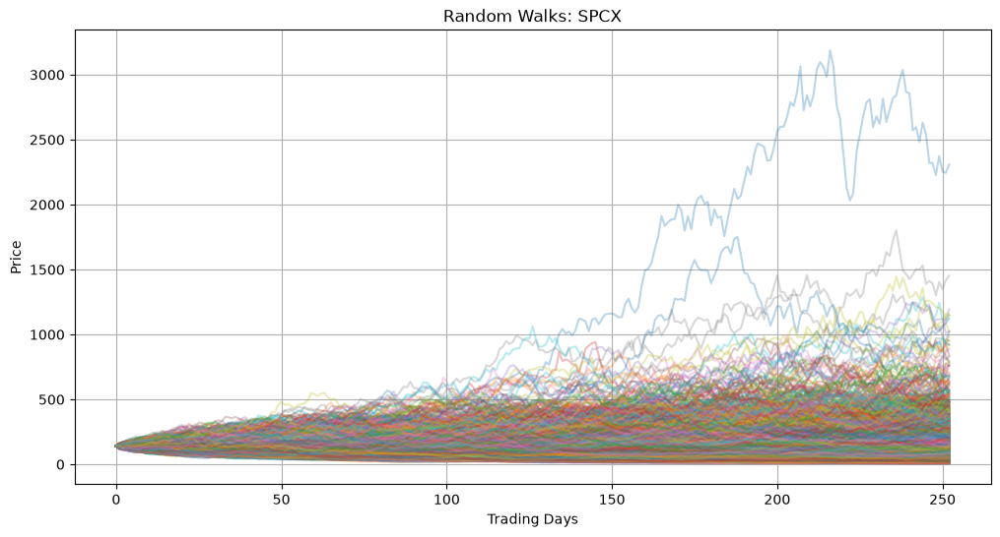

...

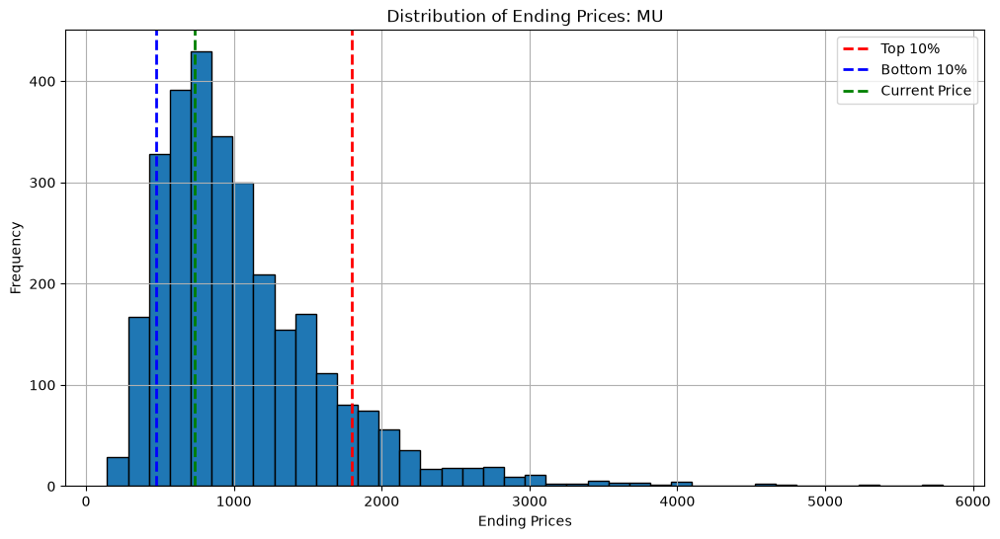

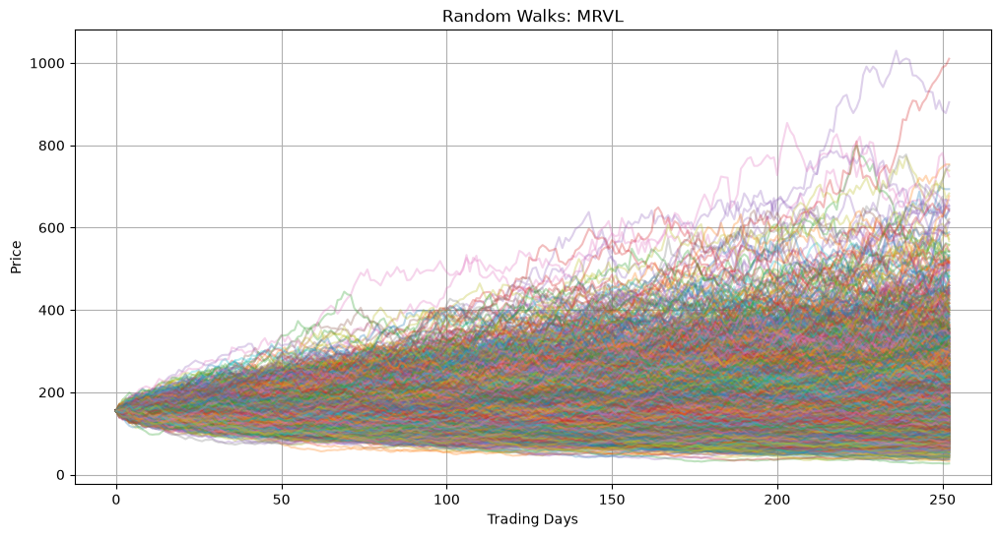

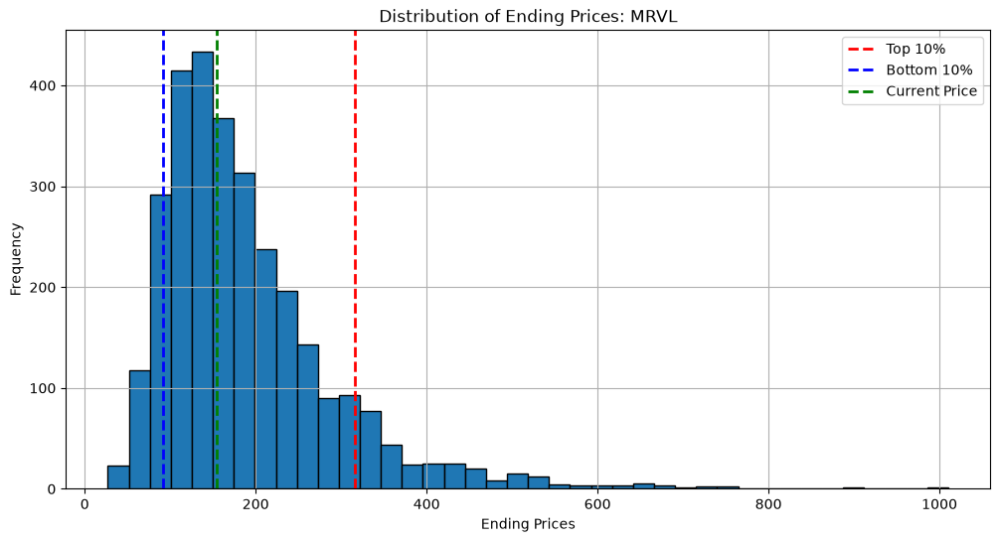

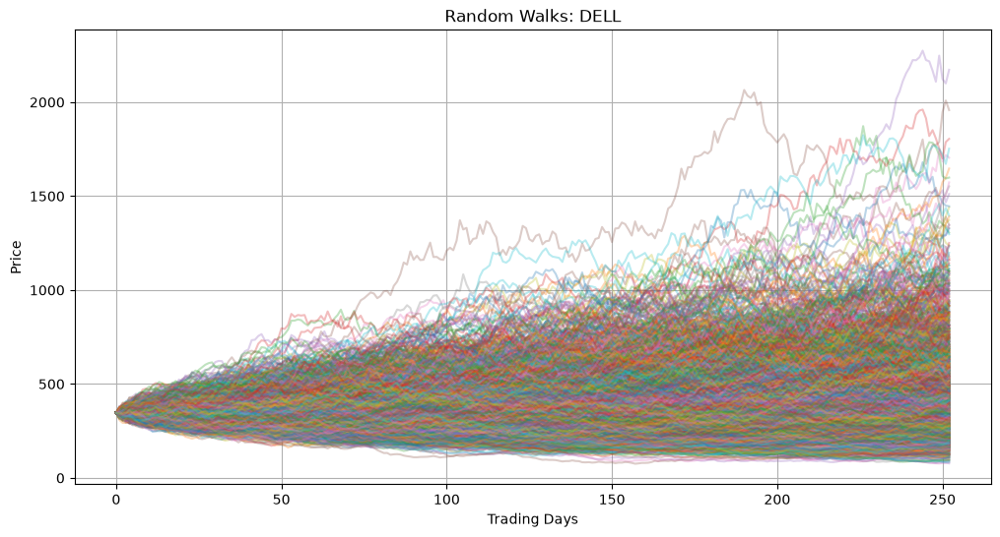

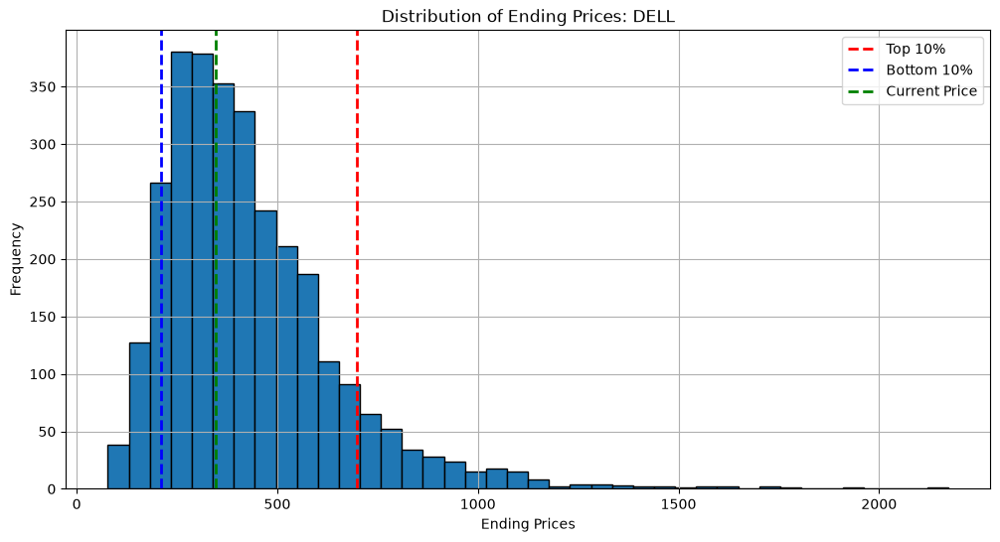

Simulated tickers: AMD, PLTR, SPCX, LITE, MRNA, KOD, TSM, META, KO, MU, MRVL, DELL


In [47]:
number_of_trials = 3000
number_of_trading_days = 252
simulation_results = {}

for ticker in stock_ticker:
    series = stock_name[('Close', ticker)].dropna()
    if series.empty:
        print(f'Skipping {ticker}: no price data')
        continue

    cagr = (series.iloc[-1] / series.iloc[0]) ** (1 / number_of_years) - 1
    std_dev = series.pct_change().std() * math.sqrt(number_of_trading_days)
    if not np.isfinite(cagr) or not np.isfinite(std_dev):
        print(f'Skipping {ticker}: invalid simulation parameters')
        continue

    ticker_closing_prices = []
    plt.figure(figsize=(12, 6))
    for i in range(number_of_trials):
        daily_returns = np.random.normal(
            cagr / number_of_trading_days,
            std_dev / math.sqrt(number_of_trading_days),
            number_of_trading_days
        ) + 1
        price_series = [float(series.iloc[-1])]
        for daily_return in daily_returns:
            price_series.append(price_series[-1] * daily_return)
        ticker_closing_prices.append(price_series[-1])
        plt.plot(price_series, alpha=0.3)

    plt.title(f'Random Walks: {ticker}')
    plt.xlabel('Trading Days')
    plt.ylabel('Price')
    plt.grid(True)
    plt.show()

    bottom_ten = float(np.percentile(ticker_closing_prices, 10))
    top_ten = float(np.percentile(ticker_closing_prices, 90))
    current_ticker_price = float(series.iloc[-1])

    plt.figure(figsize=(12, 6))
    plt.hist(ticker_closing_prices, bins=40, edgecolor='black')
    plt.axvline(top_ten, color='r', linestyle='dashed', linewidth=2, label='Top 10%')
    plt.axvline(bottom_ten, color='b', linestyle='dashed', linewidth=2, label='Bottom 10%')
    plt.axvline(current_ticker_price, color='g', linestyle='dashed', linewidth=2, label='Current Price')
    plt.xlabel('Ending Prices')
    plt.ylabel('Frequency')
    plt.title(f'Distribution of Ending Prices: {ticker}')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'histogram_{ticker}.png')
    plt.show()

    simulation_results[ticker] = {
        'closing_prices': ticker_closing_prices,
        'mean_end_price': float(np.mean(ticker_closing_prices)),
        'top_ten': float(np.percentile(ticker_closing_prices, 90)),
        'bottom_ten': float(np.percentile(ticker_closing_prices, 10)),
        'current_price': float(series.iloc[-1])
    }

# The simulation variables are stored by ticker; WAT is intentionally not selected here.
closing_prices_by_ticker = {
    ticker: result['closing_prices']
    for ticker, result in simulation_results.items()
}
print('Simulated tickers:', ', '.join(simulation_results.keys()))


In [48]:
# Store the data in a pickle file
data_to_pickle = {
    'simulation_results': simulation_results,
}

pickle_file_path = 'stock_simulation_data_amd.pkl'

with open(pickle_file_path, 'wb') as pickle_file:
    pickle.dump(data_to_pickle, pickle_file)

print(f'Data has been saved to {pickle_file_path}')


Data has been saved to stock_simulation_data_amd.pkl


In [49]:
import pandas as pd
target_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)
print("Last data date:", stock_name.index[-1].date())
print("Expected price is for approx.:", target_date.date())
print('Expected prices:')
for ticker, result in simulation_results.items():
    print(f"{ticker}: {result['mean_end_price']:.2f}")

Last data date: 2026-11-09
Expected price is for approx.: 2027-10-27
Expected prices:
AMD: 721.04
PLTR: 203.05
SPCX: 140.10
LITE: 758.42
MRNA: 313.37
KOD: 123.57
TSM: 496.27
META: 765.57
KO: 104.26
MU: 1053.06
MRVL: 188.11
DELL: 429.86


# Enhanced Monte Carlo Simulation
## Incorporating Fundamentals, Analyst Price Targets & 1-Year Projection

The basic model above uses only historical drift (CAGR) and volatility.
Here we improve it by:
1. Pulling **company fundamentals** (P/E, EPS, earnings & revenue growth, beta)
2. Pulling **analyst price targets** (mean/median/high/low) — projections by market analysts
3. Pulling **EPS estimate trends** — forward earnings projections
4. **Blending** the historical CAGR with the analyst-implied 1-year return for the drift
5. Blending long-term volatility with **recent (2-year) volatility**
6. Producing a **1-year price projection** with percentile bands and probability of gain

In [50]:
# --- 1 & 2: Company fundamentals + analyst price targets for every stock ---
tickers = stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]
fundamentals_by_ticker = {}

for ticker_symbol in tickers:
    try:
        info = yf.Ticker(ticker_symbol).info
        fundamentals_by_ticker[ticker_symbol] = {
            'currentPrice': info.get('currentPrice'),
            'targetMeanPrice': info.get('targetMeanPrice'),
            'targetMedianPrice': info.get('targetMedianPrice'),
            'targetHighPrice': info.get('targetHighPrice'),
            'targetLowPrice': info.get('targetLowPrice'),
            'recommendationKey': info.get('recommendationKey'),
            'numberOfAnalystOpinions': info.get('numberOfAnalystOpinions'),
            'trailingPE': info.get('trailingPE'), 'forwardPE': info.get('forwardPE'),
            'trailingEps': info.get('trailingEps'), 'forwardEps': info.get('forwardEps'),
            'earningsGrowth': info.get('earningsGrowth'), 'revenueGrowth': info.get('revenueGrowth'),
            'beta': info.get('beta'), 'marketCap': info.get('marketCap'),
        }
        print(f"=== Fundamentals & Analyst Projections ({ticker_symbol}) ===")
        for key, value in fundamentals_by_ticker[ticker_symbol].items():
            print(f"{key}: {value}")
    except Exception as e:
        print(f"Could not fetch fundamentals for {ticker_symbol}: {e}")
        fundamentals_by_ticker[ticker_symbol] = {}

fundamentals = fundamentals_by_ticker


=== Fundamentals & Analyst Projections (AMD) ===
currentPrice: 508.58
targetMeanPrice: 658.5292
targetMedianPrice: 650.0
targetHighPrice: 1250.0
targetLowPrice: 540.0
recommendationKey: strong_buy
numberOfAnalystOpinions: 48
trailingPE: 108.670944
forwardPE: 28.810257
trailingEps: 4.68
forwardEps: 17.65274
earningsGrowth: 0.938
revenueGrowth: 0.447
beta: 2.542
marketCap: 834115600384
=== Fundamentals & Analyst Projections (PLTR) ===
currentPrice: 169.2
targetMeanPrice: 222.25357
targetMedianPrice: 235.0
targetHighPrice: 273.0
targetLowPrice: 80.0
recommendationKey: buy
numberOfAnalystOpinions: 28
trailingPE: 119.15493
forwardPE: 66.73977
trailingEps: 1.42
forwardEps: 2.53522
earningsGrowth: 1.444
revenueGrowth: 0.959
beta: 1.61
marketCap: 407686971392
=== Fundamentals & Analyst Projections (SPCX) ===
currentPrice: 142.07
targetMeanPrice: 255.0627
targetMedianPrice: 245.0
targetHighPrice: 800.0
targetLowPrice: 70.0
recommendationKey: buy
numberOfAnalystOpinions: 37
trailingPE: 617.6957


In [51]:
# --- 3: Forward EPS and growth estimates for every stock ---
tickers = stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]
eps_trends = {}
growth_estimates_by_ticker = {}

for ticker_symbol in tickers:
    ticker = yf.Ticker(ticker_symbol)
    print(f"=== EPS and growth estimates: {ticker_symbol} ===")
    try:
        eps_trends[ticker_symbol] = ticker.eps_trend
        display(eps_trends[ticker_symbol])
    except Exception as e:
        print("EPS trend unavailable:", e)
        eps_trends[ticker_symbol] = None
    try:
        growth_estimates_by_ticker[ticker_symbol] = ticker.growth_estimates
        display(growth_estimates_by_ticker[ticker_symbol])
    except Exception as e:
        print("Growth estimates unavailable:", e)
        growth_estimates_by_ticker[ticker_symbol] = None


=== EPS and growth estimates: AMD ===


,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,currency
period,,,,,,
0q,2.92891,2.65429,2.65698,2.65404,2.65274,USD
+1q,3.29581,3.00992,3.01499,2.96022,2.95940,USD
0y,8.08621,7.58357,7.61007,7.56007,7.55674,USD
+1y,17.65274,15.96738,15.78305,15.51049,15.32965,USD


,stockTrend,indexTrend
period,,
0q,0.9143,0.2896
+1q,1.4057,0.2713
0y,0.9391,0.3326
+1y,1.1831,0.1673
LTG,NaN,0.1220


=== EPS and growth estimates: PLTR ===


,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,currency
period,,,,,,
0q,0.52023,0.46340,0.46381,0.46450,0.46015,USD
+1q,0.51941,0.48042,0.47592,0.47838,0.47485,USD
0y,1.70165,1.61381,1.61977,1.60858,1.60272,USD
+1y,2.53877,2.34997,2.35154,2.32597,2.31424,USD


,stockTrend,indexTrend
period,,
0q,0.9326,0.2896
+1q,1.0809,0.2713
0y,1.2689,0.3326
+1y,0.4919,0.1673
LTG,NaN,0.1220


... (26 outputs left out)

,stockTrend,indexTrend
period,,
0q,0.4486,0.2896
+1q,0.7003,0.2713
0y,0.4868,0.3326
+1y,0.7401,0.1673
LTG,NaN,0.1220


=== EPS and growth estimates: DELL ===


,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,currency
period,,,,,,
0q,6.55373,6.55748,6.55748,6.55726,4.25651,USD
+1q,6.74239,6.87486,6.87486,6.87486,3.92500,USD
0y,25.91371,25.89655,25.89761,25.88306,18.41304,USD
+1y,28.21240,26.80560,24.66365,24.66365,19.42750,USD


,stockTrend,indexTrend
period,,
0q,1.5304,0.2896
+1q,0.9187,0.2713
0y,1.5159,0.3326
+1y,0.1693,0.1673
LTG,NaN,0.1220


In [52]:
# --- 4 & 5: Blended drift and volatility for every stock ---
tickers = stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]
stock_metrics = {}

for ticker_symbol in tickers:
    close_series = stock_name[('Close', ticker_symbol)].dropna()
    if close_series.empty:
        print(f"Skipping {ticker_symbol}: no close-price history")
        continue

    current_price = float(close_series.iloc[-1])
    ticker_cagr = (close_series.iloc[-1] / close_series.iloc[0]) ** (1 / number_of_years) - 1
    ticker_std_dev = close_series.pct_change().std() * math.sqrt(252)
    std_dev_recent = close_series.tail(252).pct_change().std() * math.sqrt(252)
    ticker_fundamentals = fundamentals_by_ticker.get(ticker_symbol, {})
    analyst_mean_1y = ticker_fundamentals.get('targetMeanPrice')
    analyst_implied_return = (analyst_mean_1y / current_price - 1) if analyst_mean_1y else None
    blended_drift = (0.5 * ticker_cagr + 0.5 * analyst_implied_return) if analyst_implied_return is not None else ticker_cagr
    blended_volatility = 0.5 * ticker_std_dev + 0.5 * std_dev_recent

    stock_metrics[ticker_symbol] = {
        'current_price': current_price, 'cagr': ticker_cagr,
        'analyst_mean_1y': analyst_mean_1y, 'analyst_implied_return': analyst_implied_return,
        'blended_drift': blended_drift, 'long_term_volatility': ticker_std_dev,
        'recent_volatility': std_dev_recent, 'blended_volatility': blended_volatility,
    }
    print(f"=== {ticker_symbol} ===")
    print(f"Historical CAGR:            {ticker_cagr:.2%}")
    print(f"Analyst-implied 1y return:  {analyst_implied_return:.2%}" if analyst_implied_return is not None else "Analyst-implied 1y return:  N/A")
    print(f"Blended drift:              {blended_drift:.2%}")
    print(f"Blended volatility:         {blended_volatility:.2%}")


=== AMD ===
Historical CAGR:            35.03%
Analyst-implied 1y return:  29.48%
Blended drift:              32.26%
Blended volatility:         65.78%
=== PLTR ===
Historical CAGR:            17.49%
Analyst-implied 1y return:  31.36%
Blended drift:              24.42%
Blended volatility:         65.39%
=== SPCX ===
Historical CAGR:            -0.70%
Analyst-implied 1y return:  79.53%
Blended drift:              39.42%
Blended volatility:         82.96%
=== LITE ===
Historical CAGR:            22.04%
Analyst-implied 1y return:  80.75%
Blended drift:              51.39%
Blended volatility:         79.89%
=== MRNA ===
Historical CAGR:            16.13%
Analyst-implied 1y return:  -42.57%
Blended drift:              -13.22%
Blended volatility:         145.51%
=== KOD ===
Historical CAGR:            14.09%
Analyst-implied 1y return:  13.60%
Blended drift:              13.85%
Blended volatility:         162.94%
=== TSM ===
Historical CAGR:            24.13%
Analyst-implied 1y return:  50.97

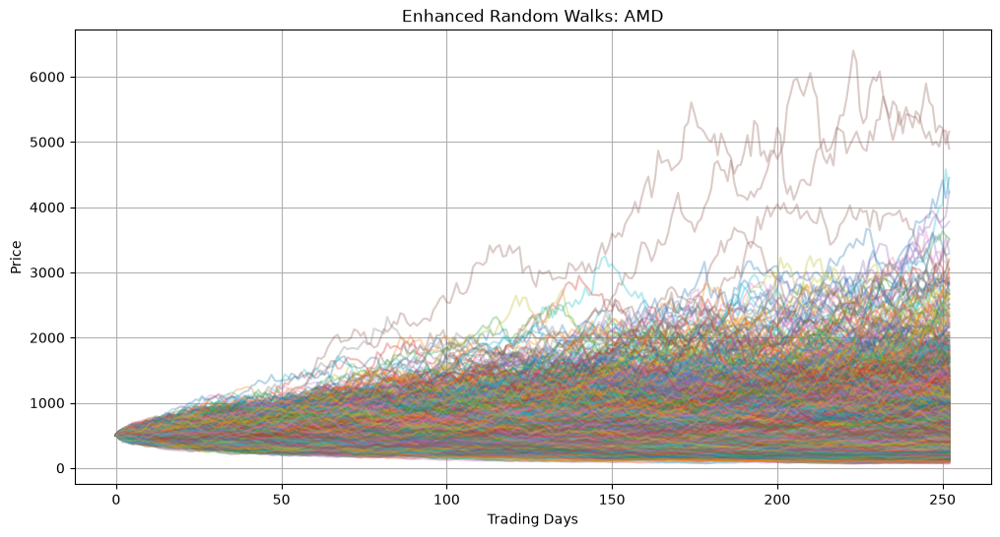

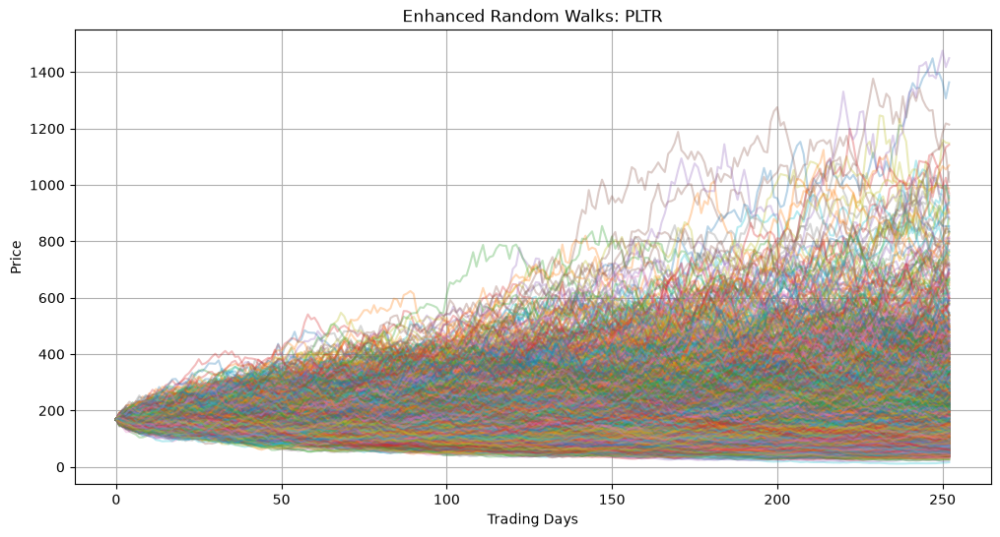

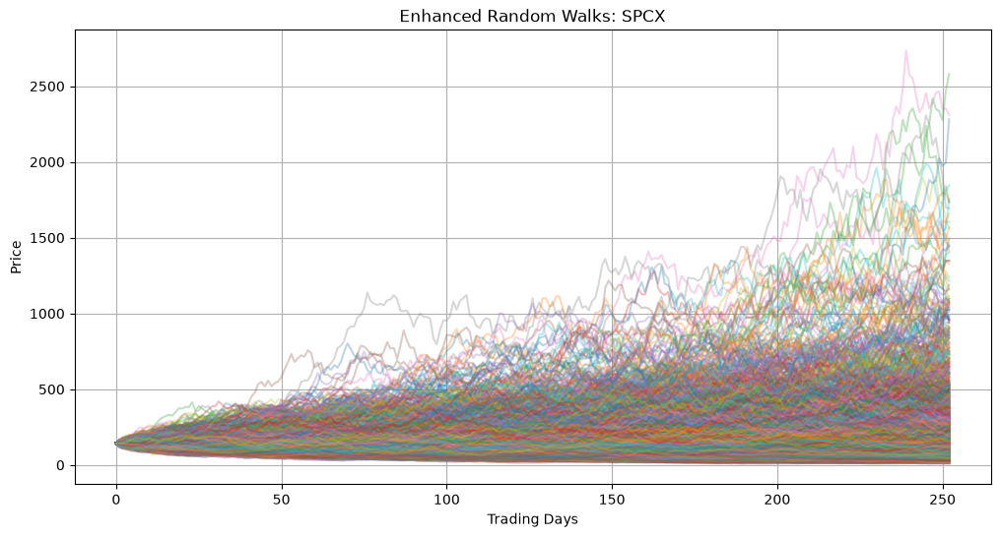

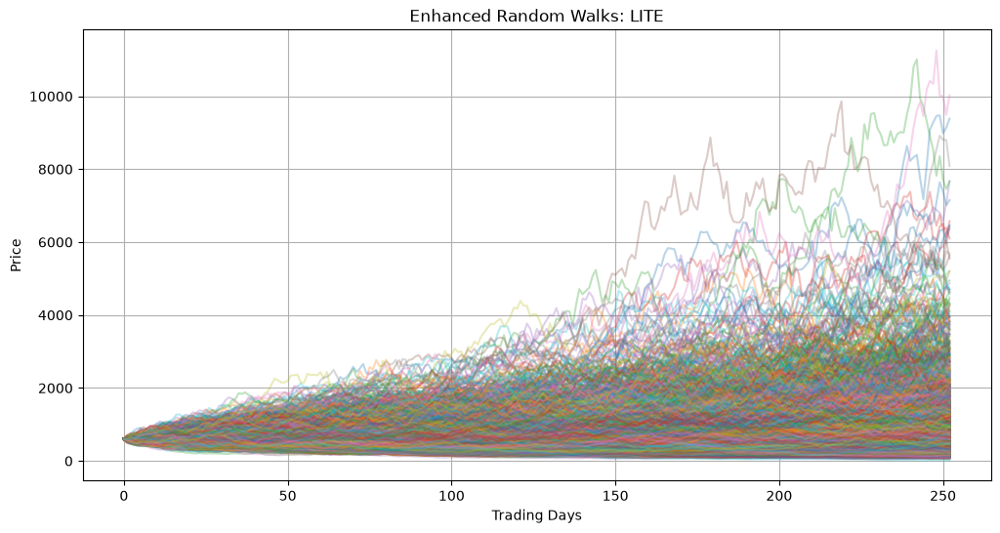

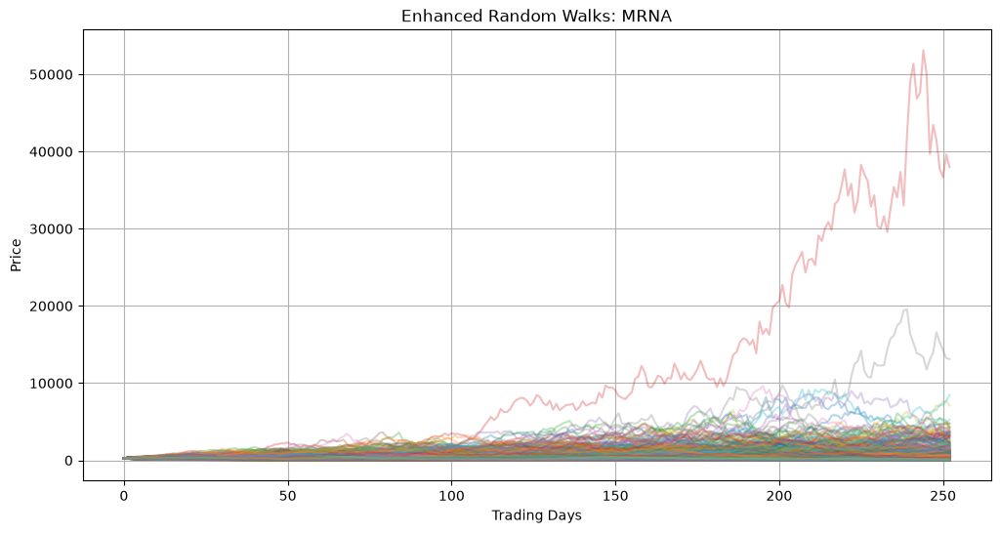

...

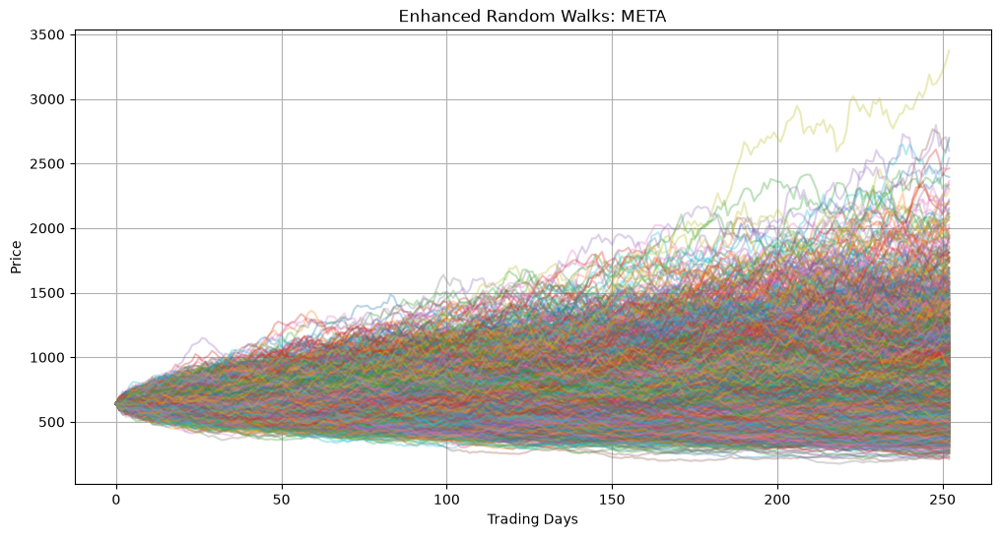

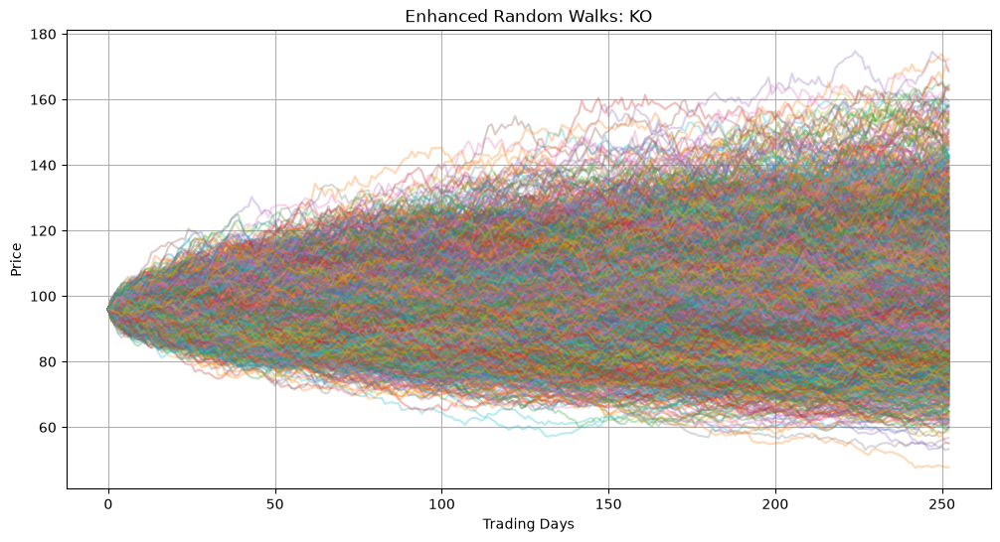

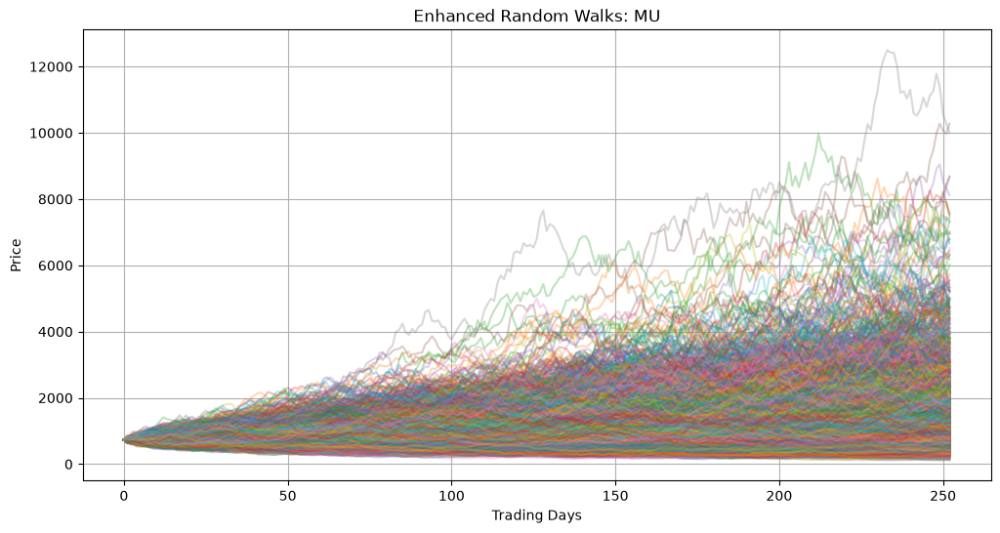

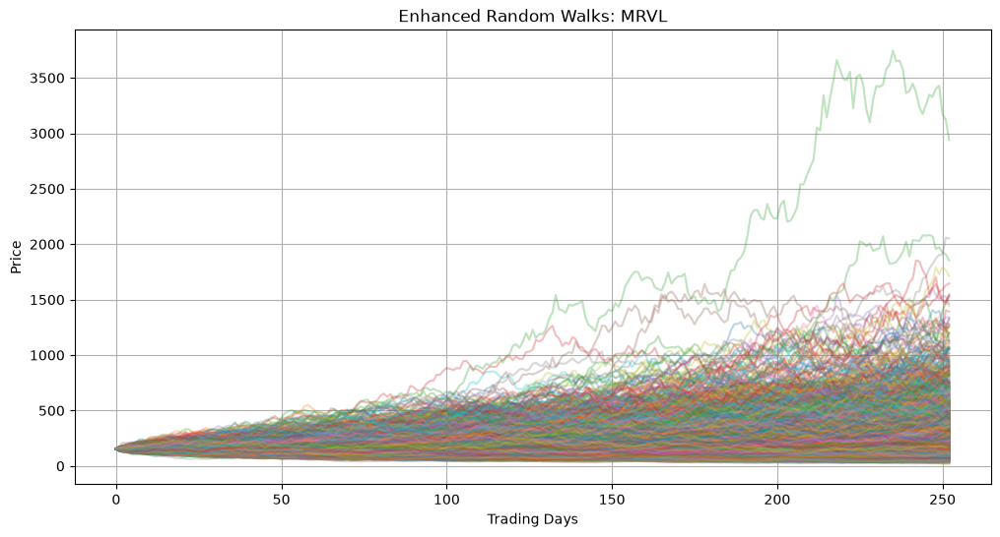

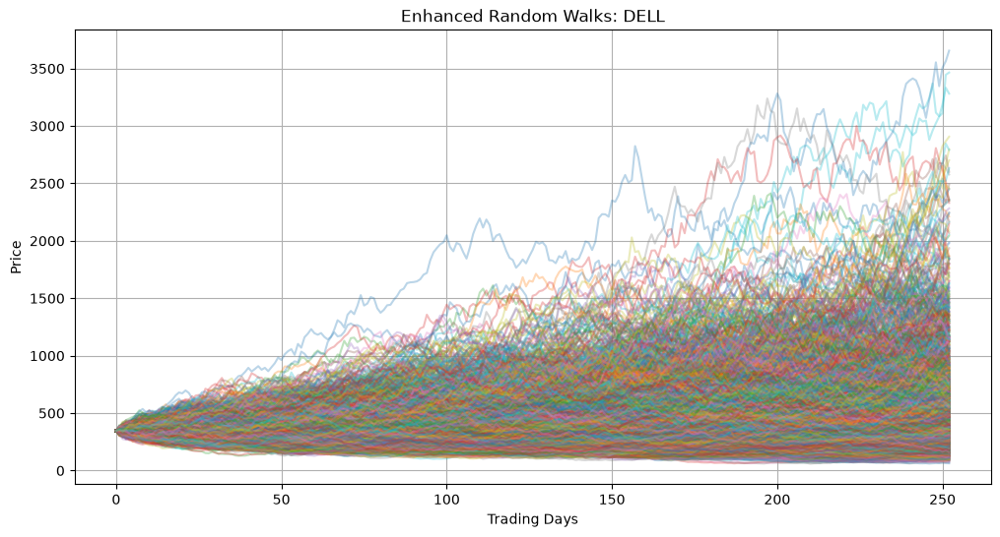

Enhanced simulations completed for: AMD, PLTR, SPCX, LITE, MRNA, KOD, TSM, META, KO, MU, MRVL, DELL


In [53]:
# --- 6: Enhanced Monte Carlo simulation for every stock ---
number_of_trials = 3000
number_of_trading_days = 252
enhanced_simulation_results = {}

for ticker_symbol, metrics in stock_metrics.items():
    ticker_closing_prices = []
    plt.figure(figsize=(12, 6))
    for i in range(number_of_trials):
        daily_returns = np.random.normal(metrics['blended_drift'] / number_of_trading_days, metrics['blended_volatility'] / math.sqrt(number_of_trading_days), number_of_trading_days) + 1
        price_series = [metrics['current_price']]
        for daily_return in daily_returns:
            price_series.append(price_series[-1] * daily_return)
        ticker_closing_prices.append(price_series[-1])
        plt.plot(price_series, alpha=0.3)

    enhanced_simulation_results[ticker_symbol] = ticker_closing_prices
    plt.title(f'Enhanced Random Walks: {ticker_symbol}')
    plt.xlabel('Trading Days')
    plt.ylabel('Price')
    plt.grid(True)
    plt.show()

print('Enhanced simulations completed for:', ', '.join(enhanced_simulation_results))


In [54]:
# --- 1-YEAR PRICE PROJECTION SUMMARY FOR EVERY STOCK ---
enhanced_projection_summary = {}
for ticker_symbol, closing_prices in enhanced_simulation_results.items():
    metrics = stock_metrics[ticker_symbol]
    current_price = metrics['current_price']
    projection_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)
    mean_price = float(np.mean(closing_prices))
    summary = {
        'current_price': current_price,
        'mean_price': mean_price,
        'p5': float(np.percentile(closing_prices, 5)),
        'p25': float(np.percentile(closing_prices, 25)),
        'p50': float(np.percentile(closing_prices, 50)),
        'p75': float(np.percentile(closing_prices, 75)),
        'p95': float(np.percentile(closing_prices, 95)),
        'prob_gain': float(np.mean(np.asarray(closing_prices) > current_price)),
        'projection_date': projection_date,
        'analyst_mean_1y': metrics['analyst_mean_1y'],
    }
    enhanced_projection_summary[ticker_symbol] = summary
    print('=' * 55)
    print(f"1-YEAR PRICE PROJECTION FOR {ticker_symbol}  ({projection_date.date()})")
    print('=' * 55)
    print(f"Current price:                 ${current_price:,.2f}")
    print(f"Expected (mean) price:         ${mean_price:,.2f}")
    print(f"Median (50th percentile):      ${summary['p50']:,.2f}")
    print(f"25th-75th percentile range:    ${summary['p25']:,.2f} - ${summary['p75']:,.2f}")
    print(f"5th-95th percentile range:     ${summary['p5']:,.2f} - ${summary['p95']:,.2f}")
    print(f"Probability of gain in 1 year: {summary['prob_gain']:.1%}")
    if summary['analyst_mean_1y']:
        print(f"Analyst mean 1y target:        ${summary['analyst_mean_1y']:,.2f}")


1-YEAR PRICE PROJECTION FOR AMD  (2027-10-27)
Current price:                 $508.58
Expected (mean) price:         $702.97
Median (50th percentile):      $567.76
25th-75th percentile range:    $369.66 - $868.88
5th-95th percentile range:     $194.21 - $1,685.47
Probability of gain in 1 year: 56.7%
Analyst mean 1y target:        $658.53
1-YEAR PRICE PROJECTION FOR PLTR  (2027-10-27)
Current price:                 $169.20
Expected (mean) price:         $213.34
Median (50th percentile):      $175.31
25th-75th percentile range:    $110.78 - $269.74
5th-95th percentile range:     $56.49 - $484.11
Probability of gain in 1 year: 52.2%
Analyst mean 1y target:        $222.25
1-YEAR PRICE PROJECTION FOR SPCX  (2027-10-27)
Current price:                 $142.07
Expected (mean) price:         $212.52
Median (50th percentile):      $149.31
25th-75th percentile range:    $83.48 - $256.17
5th-95th percentile range:     $36.68 - $603.98
Probability of gain in 1 year: 52.5%
Analyst mean 1y target:    

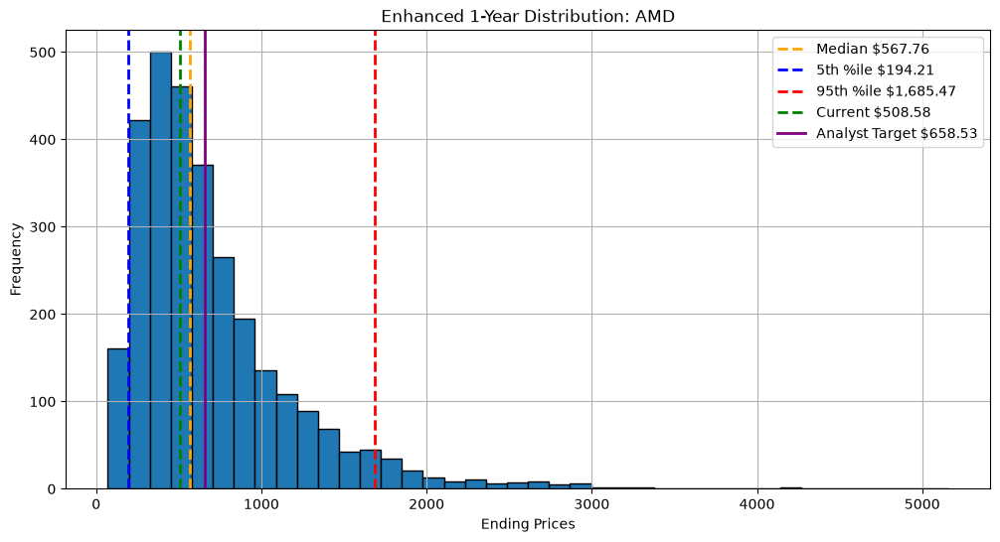

Saved AMD results to stock_simulation_data_AMD_enhanced.pkl


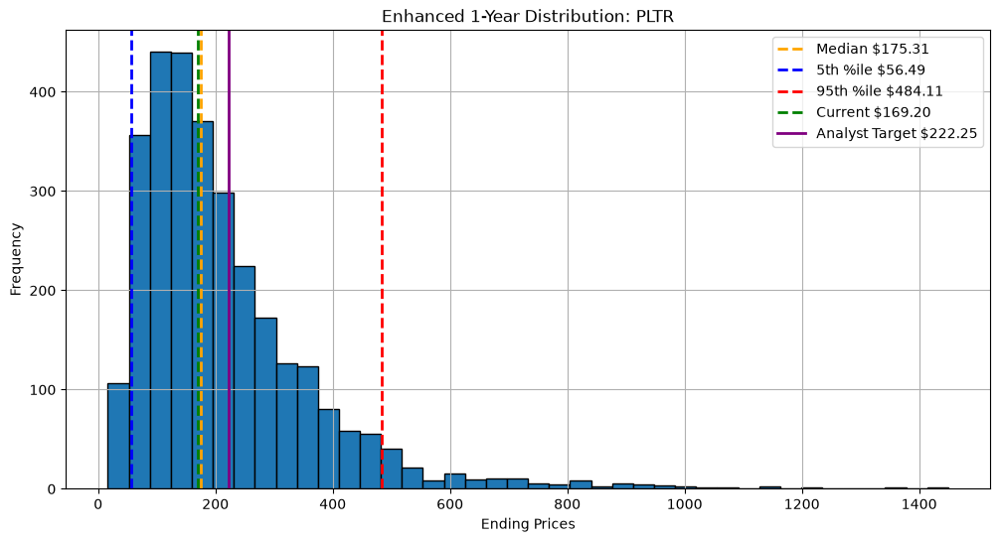

Saved PLTR results to stock_simulation_data_PLTR_enhanced.pkl


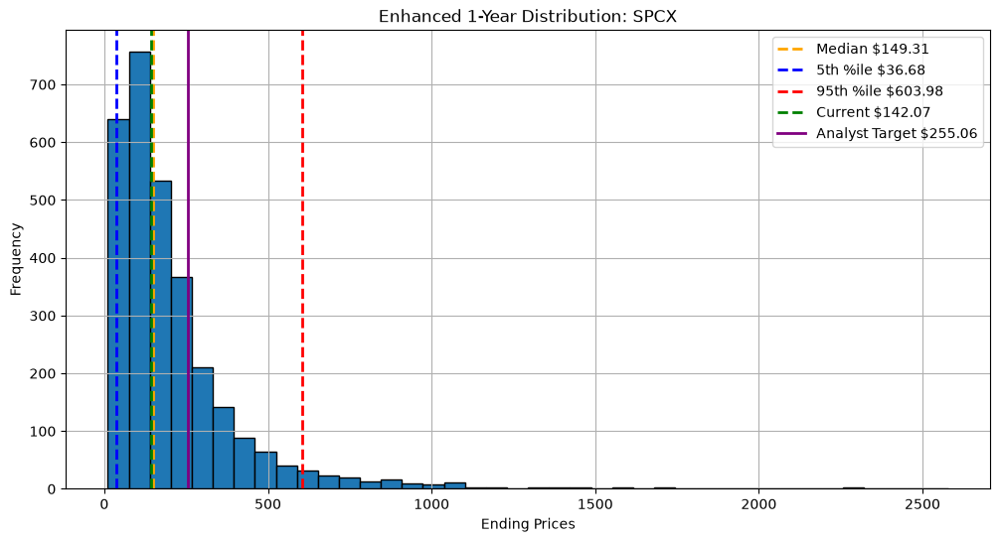

Saved SPCX results to stock_simulation_data_SPCX_enhanced.pkl


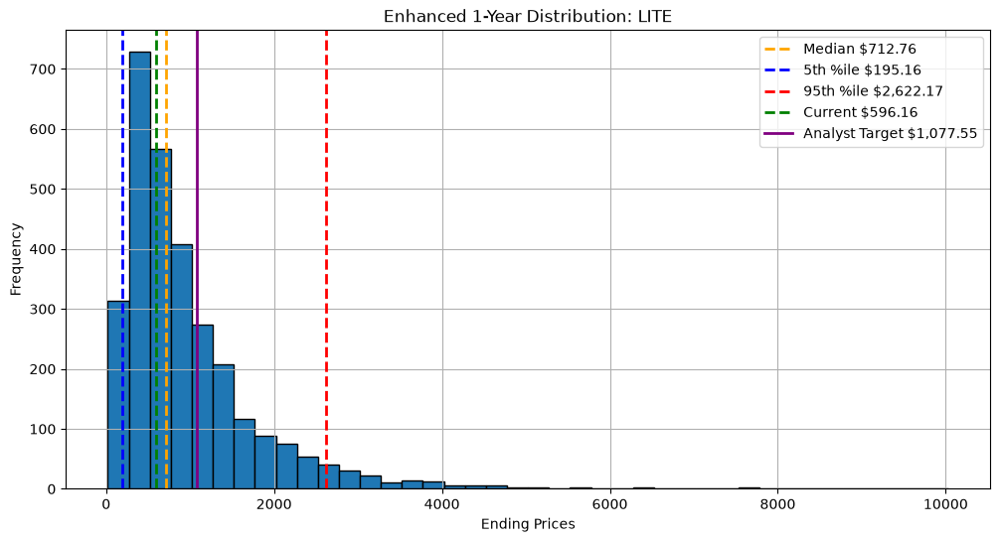

Saved LITE results to stock_simulation_data_LITE_enhanced.pkl


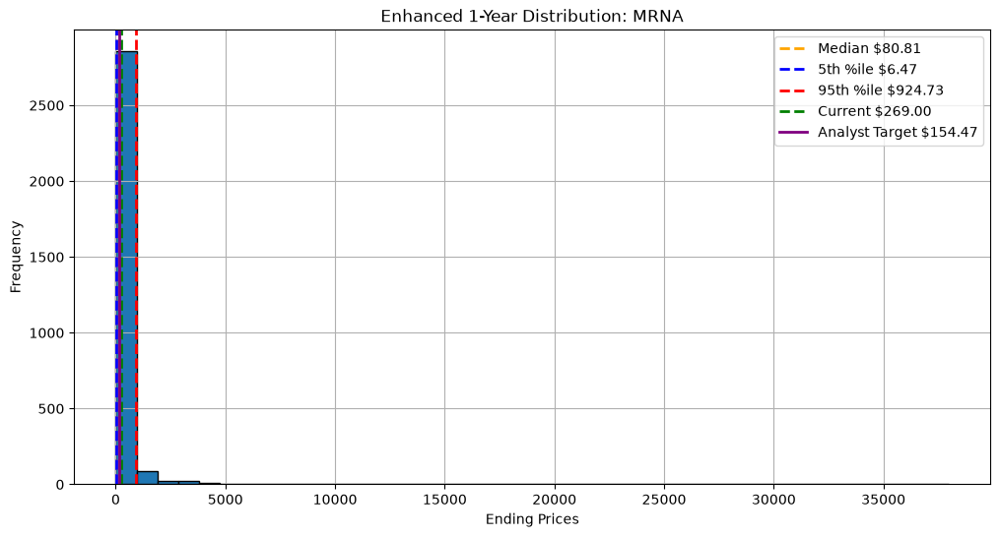

Saved MRNA results to stock_simulation_data_MRNA_enhanced.pkl


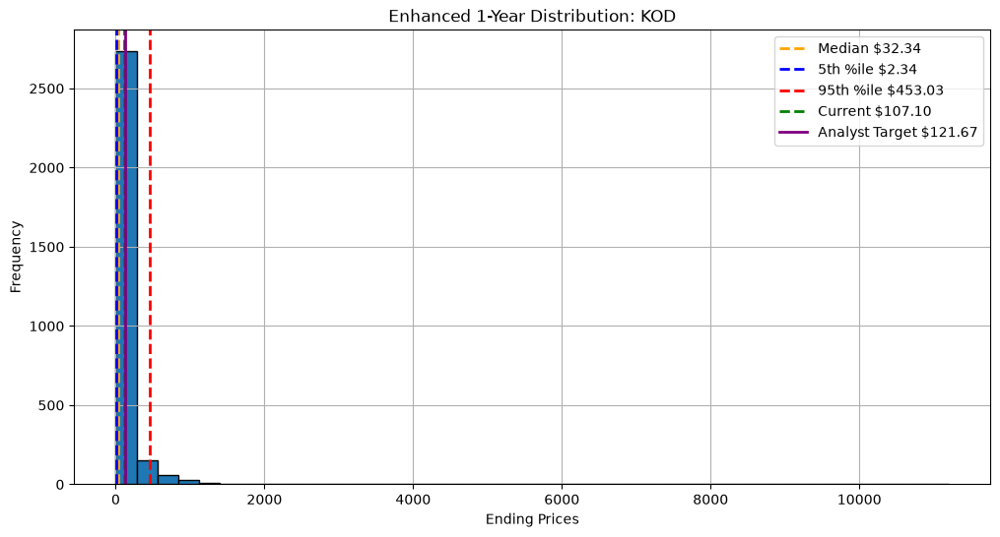

Saved KOD results to stock_simulation_data_KOD_enhanced.pkl


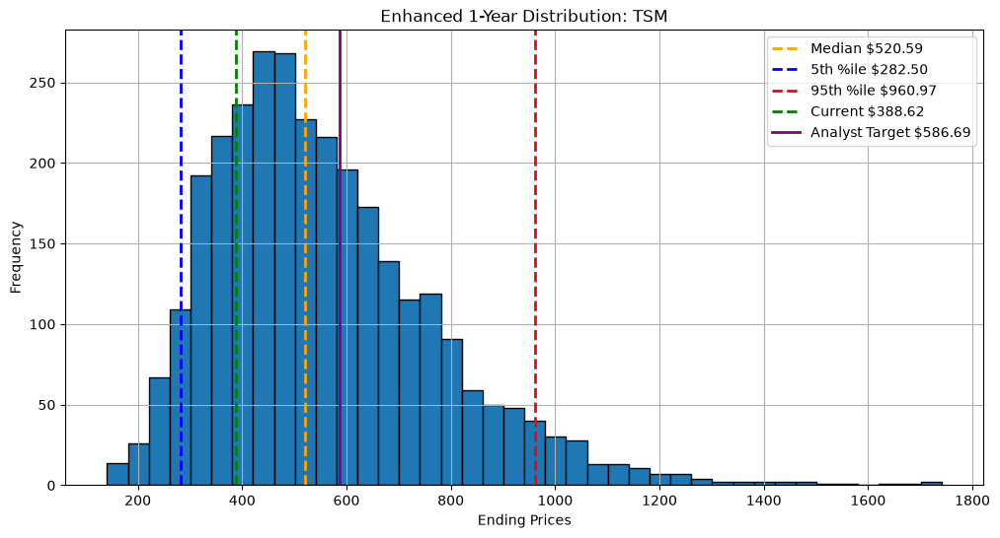

Saved TSM results to stock_simulation_data_TSM_enhanced.pkl


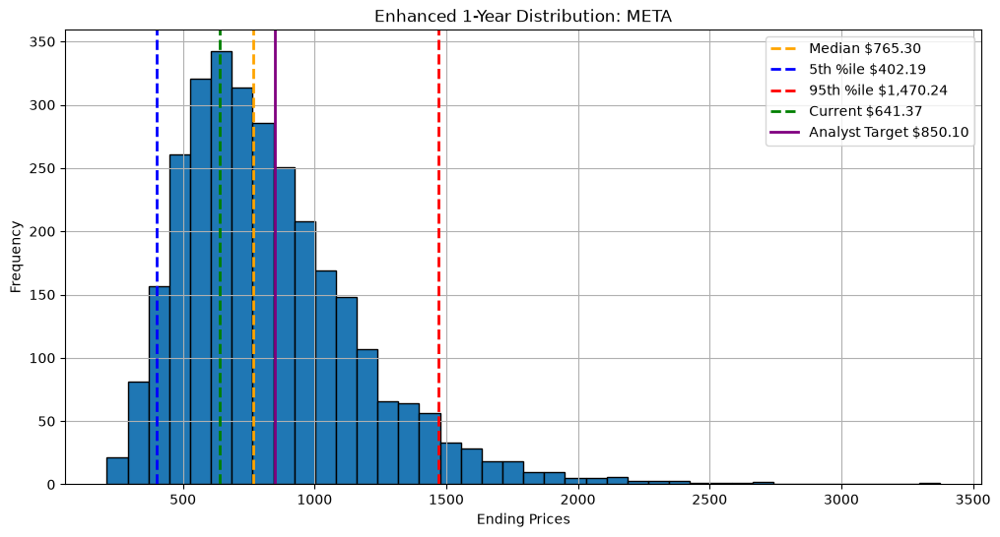

Saved META results to stock_simulation_data_META_enhanced.pkl


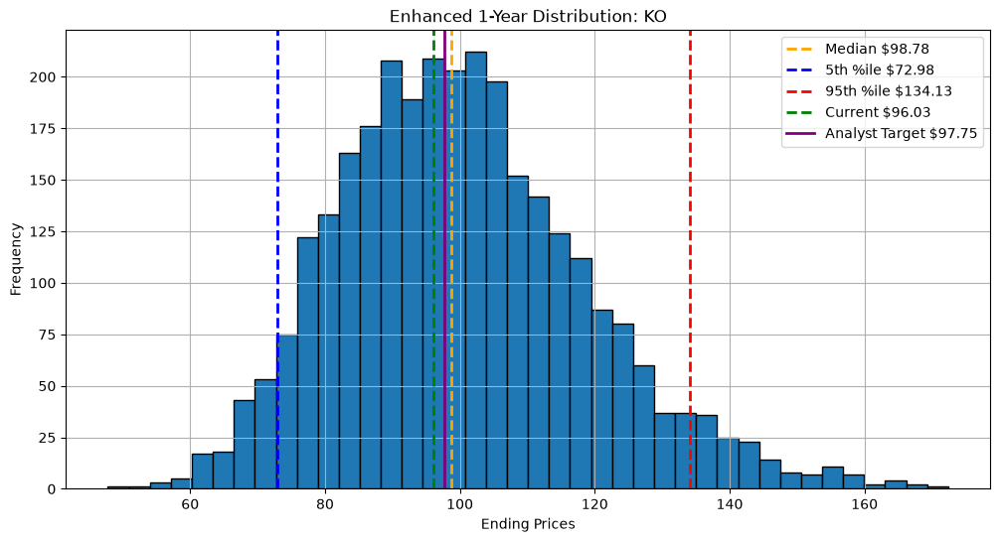

Saved KO results to stock_simulation_data_KO_enhanced.pkl


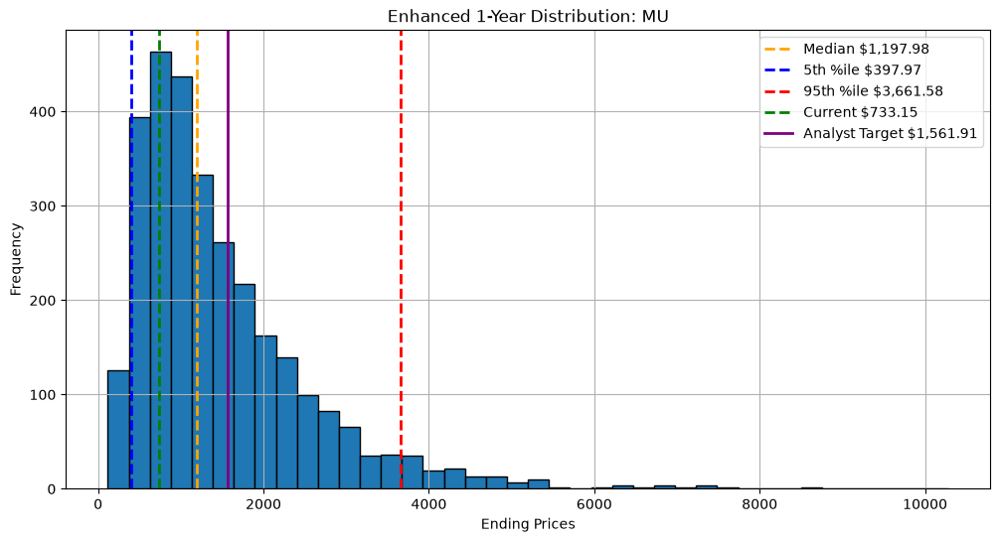

Saved MU results to stock_simulation_data_MU_enhanced.pkl


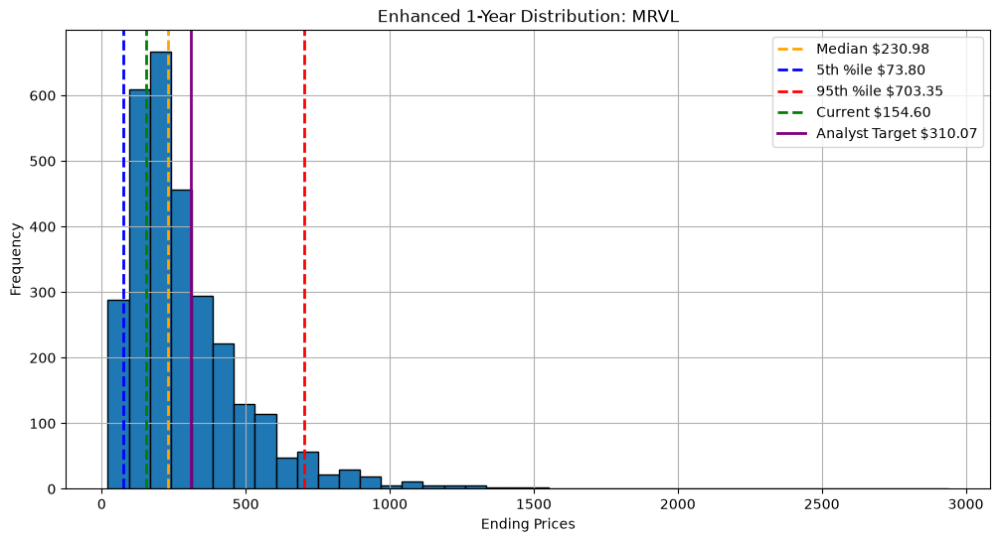

Saved MRVL results to stock_simulation_data_MRVL_enhanced.pkl


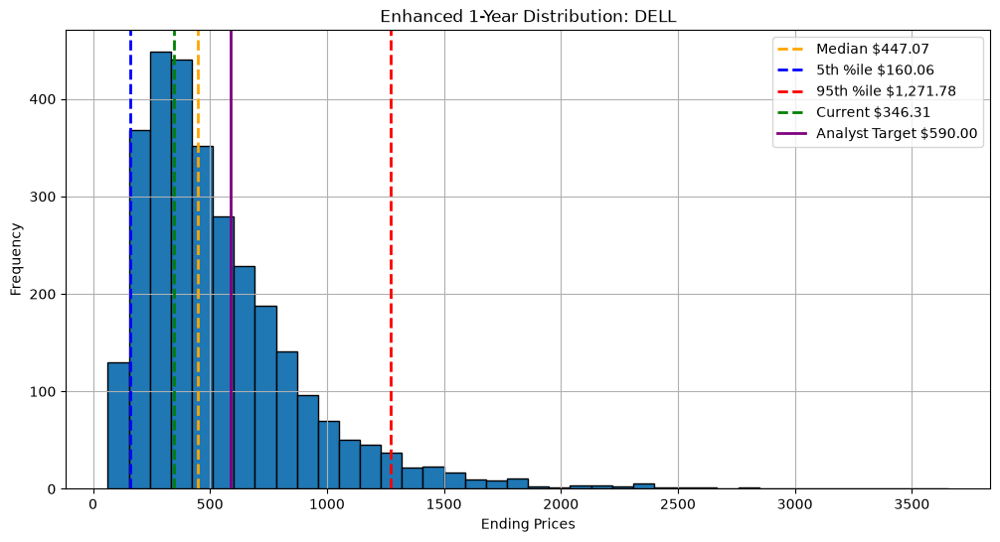

Saved DELL results to stock_simulation_data_DELL_enhanced.pkl


In [55]:
# --- Enhanced distributions and analyst overlays for every stock ---
enhanced_saved_files = {}
for ticker_symbol, closing_prices in enhanced_simulation_results.items():
    summary = enhanced_projection_summary[ticker_symbol]
    metrics = stock_metrics[ticker_symbol]
    current_price = metrics['current_price']
    plt.figure(figsize=(12, 6))
    plt.hist(closing_prices, bins=40, edgecolor='black')
    plt.axvline(summary['p50'], color='orange', linestyle='dashed', linewidth=2, label=f"Median ${summary['p50']:,.2f}")
    plt.axvline(summary['p5'], color='b', linestyle='dashed', linewidth=2, label=f"5th %ile ${summary['p5']:,.2f}")
    plt.axvline(summary['p95'], color='r', linestyle='dashed', linewidth=2, label=f"95th %ile ${summary['p95']:,.2f}")
    plt.axvline(current_price, color='g', linestyle='dashed', linewidth=2, label=f"Current ${current_price:,.2f}")
    if summary['analyst_mean_1y']:
        plt.axvline(summary['analyst_mean_1y'], color='purple', linewidth=2, label=f"Analyst Target ${summary['analyst_mean_1y']:,.2f}")
    plt.xlabel('Ending Prices')
    plt.ylabel('Frequency')
    plt.title(f"Enhanced 1-Year Distribution: {ticker_symbol}")
    plt.legend()
    plt.grid(True)
    filename = f'histogram_enhanced_{ticker_symbol}.png'
    plt.savefig(filename)
    enhanced_saved_files[ticker_symbol] = filename
    plt.show()

    enhanced_data = {
        'enhanced_closing_prices': closing_prices,
        'summary': summary,
        'fundamentals': fundamentals_by_ticker.get(ticker_symbol, {}),
        'blended_drift': metrics['blended_drift'],
        'blended_volatility': metrics['blended_volatility'],
    }
    pickle_filename = f'stock_simulation_data_{ticker_symbol}_enhanced.pkl'
    with open(pickle_filename, 'wb') as f:
        pickle.dump(enhanced_data, f)
    print(f"Saved {ticker_symbol} results to {pickle_filename}")


In [56]:
for ticker_symbol, summary in enhanced_projection_summary.items():
    current_price = summary["current_price"]
    proj_pct = (summary["mean_price"] / current_price - 1) * 100
    print(f"Stock: {ticker_symbol}")
    print(f"Calculated 1-year projected price ({summary['projection_date'].date()}): ${summary['mean_price']:,.2f} ({proj_pct:+.2f}%)")
    if summary["analyst_mean_1y"]:
        analyst_pct = (summary["analyst_mean_1y"] / current_price - 1) * 100
        print(f"Analyst 1-year target price: ${summary['analyst_mean_1y']:,.2f} ({analyst_pct:+.2f}%)")
    else:
        print("Analyst 1-year target price: N/A")


Stock: AMD
Calculated 1-year projected price (2027-10-27): $702.97 (+38.22%)
Analyst 1-year target price: $658.53 (+29.48%)
Stock: PLTR
Calculated 1-year projected price (2027-10-27): $213.34 (+26.09%)
Analyst 1-year target price: $222.25 (+31.36%)
Stock: SPCX
Calculated 1-year projected price (2027-10-27): $212.52 (+49.59%)
Analyst 1-year target price: $255.06 (+79.53%)
Stock: LITE
Calculated 1-year projected price (2027-10-27): $973.49 (+63.29%)
Analyst 1-year target price: $1,077.55 (+80.75%)
Stock: MRNA
Calculated 1-year projected price (2027-10-27): $249.81 (-7.14%)
Analyst 1-year target price: $154.47 (-42.57%)
Stock: KOD
Calculated 1-year projected price (2027-10-27): $114.78 (+7.17%)
Analyst 1-year target price: $121.67 (+13.60%)
Stock: TSM
Calculated 1-year projected price (2027-10-27): $556.21 (+43.12%)
Analyst 1-year target price: $586.69 (+50.97%)
Stock: META
Calculated 1-year projected price (2027-10-27): $830.91 (+29.55%)
Analyst 1-year target price: $850.10 (+32.54%)
Sto

# US Stock Screener — Top 15 by Projected 1-Year Return
Runs the enhanced Monte Carlo projection (blended drift = 50% historical CAGR + 50% analyst-implied return) across a large list of liquid US stocks, then ranks them by projected 1-year return.

Notes:
- "All US stocks" (6000+) would take hours to download; this screens a curated universe of S&P 500 + major tech/growth names. Extend `TICKERS` as needed.
- Requires internet; yfinance rate limits may throttle long runs. Progress is printed.
- Results include: current price, projected 1yr price, projected % return, analyst mean target, and probability of gain.

In [57]:
def _read_tables(url):
    """Read HTML tables from a URL (Wikipedia blocks default urllib, so use requests + UA header)."""
    import io
    import pandas as pd
    html = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}).text
    return pd.read_html(io.StringIO(html))


def get_nasdaq100_tickers():
    url = 'https://en.wikipedia.org/wiki/List_of_NASDAQ-100_companies'
    for t in _read_tables(url):
        # Wikipedia has used both 'Ticker' and 'Symbol' as the column name
        for col in ('Ticker', 'Symbol'):
            if col in t.columns:
                return t[col].astype(str).str.replace('.', '-', regex=False).tolist()
    return []


def get_sp500_tickers():
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    for t in _read_tables(url):
        for col in ('Symbol', 'Ticker'):
            if col in t.columns:
                return t[col].astype(str).str.replace('.', '-', regex=False).tolist()
    return []

In [58]:
import pandas as pd


def screen_ticker(tkr, trials=1000, verbose=False):
    """Run the enhanced MC projection for one ticker. Returns a dict or None on failure."""
    try:
        data = yf.download(tkr, start='2009-01-01', progress=False)
        if data is None or len(data) < 260:
            if verbose:
                print(f"  {tkr}: download returned {0 if data is None else len(data)} rows")
            return None
        close = data[('Close', tkr)] if ('Close', tkr) in data.columns else data['Close']
        close = close.dropna()
        if len(close) < 260:
            return None

        # Historical stats
        growth = close.iloc[-1] / close.iloc[0]
        years = (close.index[-1] - close.index[0]).days / 365.0
        if years <= 0:
            return None
        cagr_t = (growth ** (1/years)) - 1
        vol_long = close.pct_change().std() * math.sqrt(252)
        # Series.last() was removed in pandas 3.x — use a date slice instead
        recent = close[close.index >= close.index[-1] - pd.DateOffset(years=2)]
        vol_recent = recent.pct_change().std() * math.sqrt(252)
        vol = 0.5 * vol_long + 0.5 * (
            vol_recent if not math.isnan(vol_recent) else vol_long
        )

        if math.isnan(vol_long) or math.isnan(vol):
            return None

        current = float(close.iloc[-1])
        try:
            analyst_target = yf.Ticker(tkr).info.get('targetMeanPrice')
        except Exception:
            analyst_target = None

        analyst_return = None
        if analyst_target is not None and float(analyst_target) > 0:
            analyst_target = float(analyst_target)
            analyst_return = analyst_target / current - 1

        drift = 0.5 * cagr_t + 0.5 * analyst_return if analyst_return is not None else cagr_t

        endings = []
        for _ in range(trials):
            daily_returns = np.random.normal(
                drift / 252,
                vol / math.sqrt(252),
                252
            ) + 1
            projected_price = current
            for daily_return in daily_returns:
                projected_price *= daily_return
            endings.append(projected_price)

        projected_1y = float(np.mean(endings))
        return {
            'ticker': tkr,
            'current': current,
            'projected_1y': projected_1y,
            'proj_return_pct': (projected_1y / current - 1) * 100,
            'analyst_target': analyst_target,
            'prob_gain_pct': 100 * np.mean(np.asarray(endings) > current),
        }
    except Exception as exc:
        if verbose:
            print(f"  {tkr}: {exc}")
        return None

In [59]:
# --- Quick diagnostic: run 2 tickers with verbose errors ---
for t in ['AAPL', 'MSFT']:
    screen_ticker(t, verbose=True)
print("Diagnostic done. If both printed 'download returned 0 rows', you are rate-limited — wait 15-30 min.")


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

Diagnostic done. If both printed 'download returned 0 rows', you are rate-limited — wait 15-30 min.


In [60]:
# --- Build the screening universe and run the screener -> `results` ---
TICKERS = sorted(set(get_sp500_tickers() + get_nasdaq100_tickers()))
print(f"Screening {len(TICKERS)} tickers (this can take a while)...")

results = []
for i, tkr in enumerate(TICKERS, 1):
    r = screen_ticker(tkr)
    if r:
        results.append(r)
    if i % 50 == 0 or i == len(TICKERS):
        print(f"  {i}/{len(TICKERS)} done — {len(results)} successful")

print(f"Screen complete: {len(results)}/{len(TICKERS)} tickers produced results")

Screening 518 tickers (this can take a while)...


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

  50/518 done — 50 successful


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

  100/518 done — 100 successful


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

... (13 outputs left out)

$TROW: possibly delisted; no price data found  (1d 2009-01-01 -> 2026-11-10)

1 Failed download:
['TROW']: possibly delisted; no price data found  (1d 2009-01-01 -> 2026-11-10)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)
$TRV: possibly delisted; no price data found  (1d 2009-01-01 -> 2026-11-10)

1 Failed download:

  500/518 done — 368 successful


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

  518/518 done — 386 successful
Screen complete: 386/518 tickers produced results


In [61]:
# --- Top 15 by projected 1-year return ---
top15 = sorted(results, key=lambda x: x['proj_return_pct'], reverse=True)[:15]

print("=" * 80)
print("TOP 15 US STOCKS BY PROJECTED 1-YEAR RETURN")
print("=" * 80)
print(f"{'#':>2} {'Ticker':<7} {'Current':>10} {'Proj 1Y':>10} {'Proj %':>9} {'Analyst Tgt':>12} {'P(gain)':>8}")
print("-" * 80)
for rank, r in enumerate(top15, 1):
    atgt = f"${r['analyst_target']:,.2f}" if r['analyst_target'] else "N/A"
    print(f"{rank:>2} {r['ticker']:<7} ${r['current']:>9,.2f} ${r['projected_1y']:>9,.2f} "
          f"{r['proj_return_pct']:>+8.1f}% {atgt:>12} {r['prob_gain_pct']:>7.1f}%")
print("=" * 80)

# As a DataFrame
import pandas as pd
top15_df = pd.DataFrame(top15)
display(top15_df)


TOP 15 US STOCKS BY PROJECTED 1-YEAR RETURN
 # Ticker     Current    Proj 1Y    Proj %  Analyst Tgt  P(gain)
--------------------------------------------------------------------------------
 1 NBIS    $   141.45 $   478.91   +238.6%      $278.05    71.2%
 2 CRWV    $    48.98 $   135.43   +176.5%      $131.53    62.6%
 3 MU      $   733.15 $ 1,562.82   +113.2%    $1,561.91    78.0%
 4 GEV     $   829.34 $ 1,738.31   +109.6%    $1,182.83    85.4%
 5 WDC     $   289.78 $   571.70    +97.3%      $613.38    79.5%
 6 NVDA    $   178.67 $   347.20    +94.3%      $326.92    89.4%
 7 ALAB    $   216.87 $   415.05    +91.4%      $347.18    59.6%
 8 FLEX    $    78.17 $   143.28    +83.3%      $156.50    81.7%
 9 CIEN    $   269.33 $   486.21    +80.5%      $512.99    72.7%
10 LITE    $   596.16 $ 1,058.36    +77.5%    $1,077.55    66.2%
11 VRT     $   200.47 $   350.10    +74.6%      $337.54    68.4%
12 ALNY    $   156.61 $   271.81    +73.6%      $302.56    78.6%
13 MRVL    $   154.60 $   265.

,ticker,current,projected_1y,proj_return_pct,analyst_target,prob_gain_pct
0,NBIS,141.449997,478.911473,238.572982,278.05000,71.2
1,CRWV,48.980000,135.426445,176.493357,131.52632,62.6
2,MU,733.150024,1562.818279,113.164868,1561.91110,78.0
3,GEV,829.340027,1738.307202,109.601267,1182.83180,85.4
4,WDC,289.779999,571.695616,97.286085,613.37500,79.5
5,NVDA,178.669998,347.198296,94.323781,326.91754,89.4
6,ALAB,216.869995,415.045983,91.380086,347.17773,59.6
7,FLEX,78.169998,143.283196,83.296917,156.50000,81.7
8,CIEN,269.329987,486.205949,80.524254,512.99070,72.7
9,LITE,596.159973,1058.364660,77.530312,1077.55400,66.2
